# Real-world datasets combined

In [1]:
from mol_faith.notebooks.results_analysis.shared import (
    REAL_WORLD_DATA,
    REAL_WORLD_DATASETS,
    REAL_WORLD_RESULTS,
    REAL_WORLD_TARGET_COLORS,
    aggregate_and_merge_normalized_fid,
    analyze_std_by_sign_effect,
    calculate_per_task_rank_panel,
    calculate_ranking_excluding_sign_effect,
    combine_and_calculate_variance,
    compute_effect_sizes,
    count_positive_fid_negative_random,
    create_grouped_boxplot,
    create_grouped_boxplot_with_violin,
    create_grouped_violinplot,
    fit_fid_ols,
    kruskal_by,
    load_raw_data,
    load_raw_data_all_thres,
    perform_pca,
    plot_fidelity_by_threshold,
    plot_fidelity_by_threshold_per_target,
    plot_pca,
    process_fidelity_df,
    summarize_molecule_stats,
)

In [2]:
HUE_ORDER = ['FXA_logD', 'FXA_logS', 'ABL1', 'LogP']
OUTPUT_DIR = REAL_WORLD_RESULTS / 'result_plots' / 'combined'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
target_data = {
    label: process_fidelity_df(load_raw_data(REAL_WORLD_RESULTS / folder, target_name))
    for label, (folder, target_name) in REAL_WORLD_DATASETS.items()
}
table_data = {label.replace('_', ' '): df for label, df in target_data.items()}

logp: 241,382 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
206,882 rows | {'faithful': 143196, 'unfaithful': 63686} | normalized_fid in [-1.000, 1.000]


logd: 17,496 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
14,996 rows | {'faithful': 10227, 'unfaithful': 4769} | normalized_fid in [-1.000, 1.000]


logs: 16,891 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
14,391 rows | {'faithful': 9537, 'unfaithful': 4854} | normalized_fid in [-1.000, 1.000]


abl1: 23,975 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
20,550 rows | {'faithful': 11294, 'unfaithful': 9256} | normalized_fid in [-1.000, 1.000]


## Boxplots

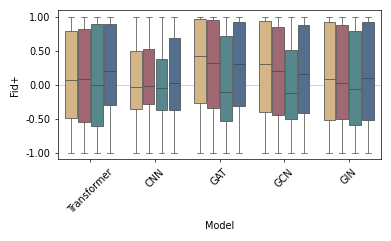

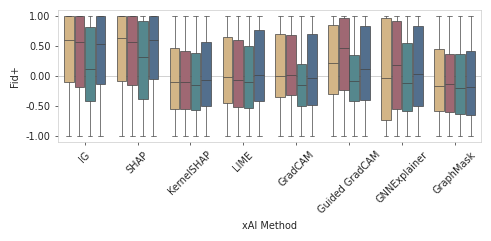

In [4]:
model_fig = create_grouped_boxplot(target_data, 'normalized_fid', 'model', figsize=(4, 2.5),
                                   target_colors=REAL_WORLD_TARGET_COLORS, hue_order=HUE_ORDER)
create_grouped_boxplot(target_data, 'normalized_fid', 'explanation_method', figsize=(5, 2.5),
                       target_colors=REAL_WORLD_TARGET_COLORS, hue_order=HUE_ORDER, output_dir=OUTPUT_DIR,
                       reference_fig=model_fig, enable_reference_yticks=True);

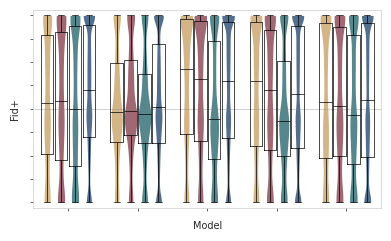

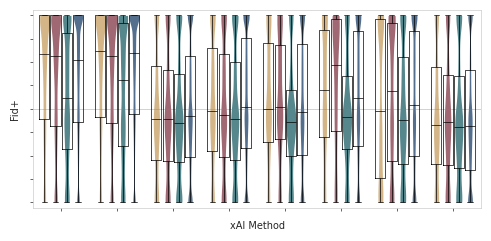

In [5]:
for group_col, figsize in (('model', (4, 2.5)), ('explanation_method', (5, 2.5))):
    create_grouped_boxplot_with_violin(target_data, 'normalized_fid', group_col, figsize=figsize,
                                       target_colors=REAL_WORLD_TARGET_COLORS, hue_order=HUE_ORDER,
                                       output_dir=OUTPUT_DIR)

## PCA

Guided GradCAM is NaN for the CNN, so it is not shown in the PCA.

PCA on ['fid_normalized_median_LogP', 'fid_normalized_median_FXA_logD', 'fid_normalized_median_FXA_logS', 'fid_normalized_median_ABL1'], explained variance ratio [0.89230024 0.09069617]


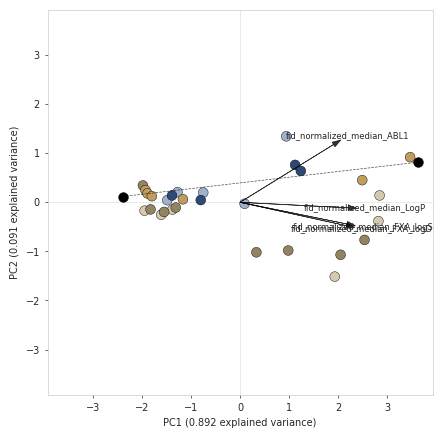

In [6]:
pca_df, pca, _, loadings, fid_columns = perform_pca(aggregate_and_merge_normalized_fid(target_data))
plot_pca(pca_df, pca, loadings, fid_columns, show_loadings=True, figsize=(5, 5), point_size=50, labelsize=7,
         tick_label_size=7, save_path=OUTPUT_DIR / 'pca_plot_loadings.svg');

## Violin plots

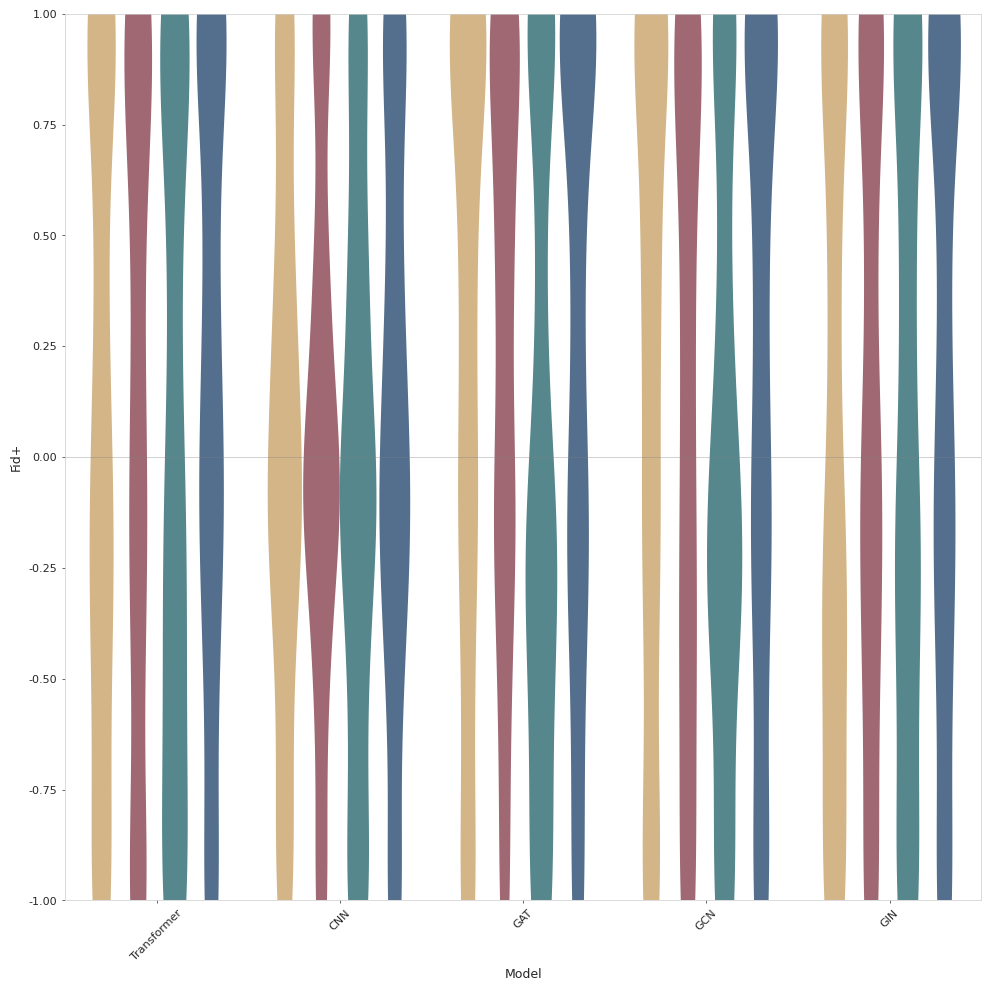

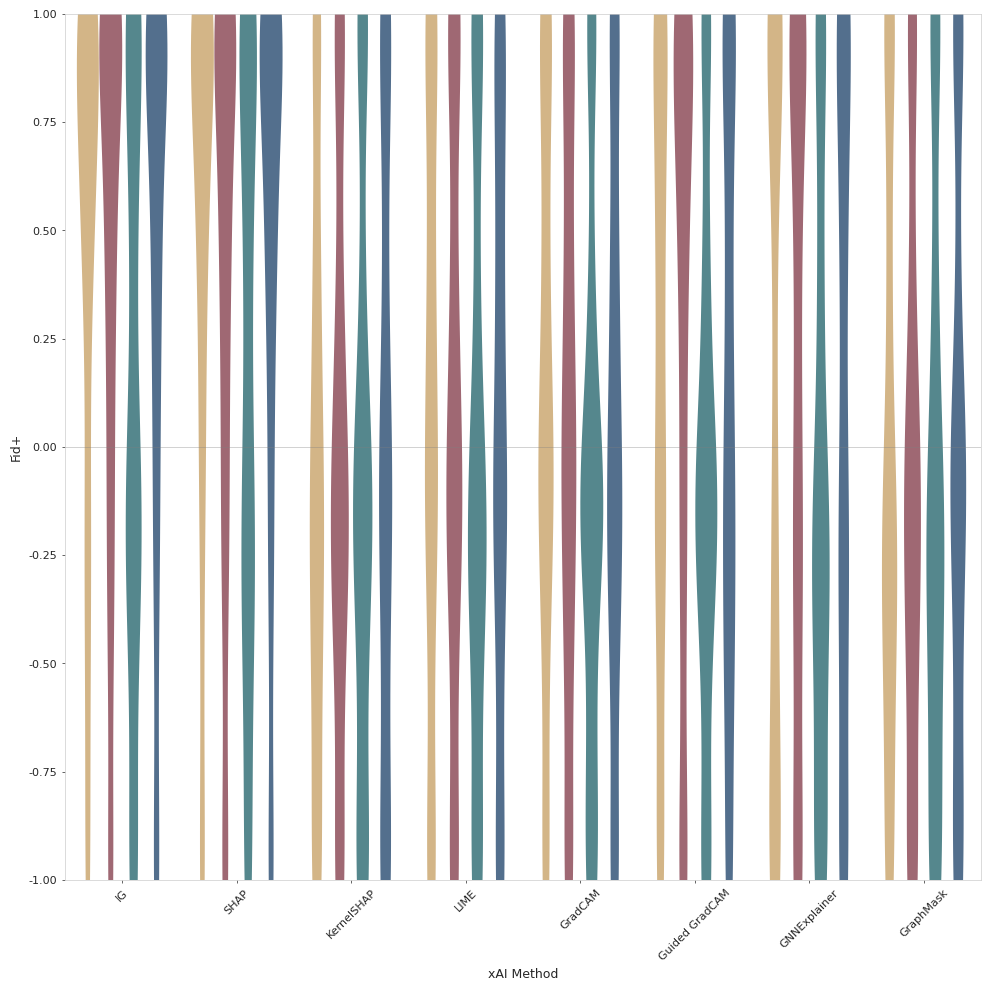

In [7]:
for group_col in ('model', 'explanation_method'):
    create_grouped_violinplot(target_data, 'normalized_fid', group_col, figsize=(10, 10),
                              target_colors=REAL_WORLD_TARGET_COLORS, hue_order=HUE_ORDER)

## Sign normalization effect

In [8]:
for by in ({}, {'by_model': True}, {'by_model': True, 'by_method': True}):
    display(count_positive_fid_negative_random(target_data, **by))

,dataset,n_cases,n_total,pct_cases
0,LogP,65901,206882,31.85
1,FXA_logD,4664,14996,31.10
2,FXA_logS,4546,14391,31.59
3,ABL1,5964,20550,29.02


,dataset,model,n_cases,n_total,pct_cases
0,LogP,CNN,11581,41400,27.97
1,LogP,GAT,12977,41400,31.35
2,LogP,GCN,17786,55082,32.29
3,LogP,GIN,14706,41400,35.52
4,LogP,Transformer,8851,27600,32.07
5,FXA_logD,CNN,652,3000,21.73
6,FXA_logD,GAT,997,3000,33.23
7,FXA_logD,GCN,1348,3996,33.73
8,FXA_logD,GIN,1034,3000,34.47
9,FXA_logD,Transformer,633,2000,31.65


,dataset,model,explanation_method,n_cases,n_total,pct_cases
0,LogP,CNN,GradCAM,1925,6900,27.90
1,LogP,CNN,Guided GradCAM,1981,6900,28.71
2,LogP,CNN,IG,1994,6900,28.90
3,LogP,CNN,KernelSHAP,1780,6900,25.80
4,LogP,CNN,LIME,1923,6900,27.87
...,...,...,...,...,...,...
114,ABL1,GIN,SHAP,242,685,35.33
115,ABL1,Transformer,IG,236,685,34.45
116,ABL1,Transformer,KernelSHAP,239,685,34.89
117,ABL1,Transformer,LIME,233,685,34.01


In [9]:
for group_col in ('model', 'explanation_method'):
    display(calculate_ranking_excluding_sign_effect(target_data, group_col=group_col))

Excluded 81,075 of 256,819 rows (31.57%) with the sign effect (fid_plus and fid_plus_random have opposite signs).


,data,rank,model,n,mean,median,std
0,excluding sign effect,1,GAT,35296,0.100,0.057,0.526
1,excluding sign effect,2,Transformer,23187,0.066,0.013,0.498
2,excluding sign effect,3,GCN,46610,0.048,-0.022,0.526
3,excluding sign effect,4,CNN,37315,0.009,-0.034,0.461
4,excluding sign effect,5,GIN,33336,0.023,-0.052,0.542
5,all data,1,GAT,51510,0.198,0.272,0.687
6,all data,2,Transformer,34340,0.161,0.178,0.685
7,all data,3,GCN,68449,0.131,0.128,0.701
8,all data,4,GIN,51510,0.102,0.064,0.730
9,all data,5,CNN,51010,0.079,0.000,0.646


Excluded 81,075 of 256,819 rows (31.57%) with the sign effect (fid_plus and fid_plus_random have opposite signs).


,data,rank,explanation_method,n,mean,median,std
0,excluding sign effect,1,SHAP,28355,0.254,0.360,0.520
1,excluding sign effect,2,IG,28580,0.207,0.287,0.524
2,excluding sign effect,3,Guided GradCAM,11327,0.039,-0.018,0.497
3,excluding sign effect,4,LIME,29917,-0.002,-0.053,0.484
4,excluding sign effect,5,GNNExplainer,17064,0.004,-0.060,0.529
5,excluding sign effect,6,GradCAM,12086,-0.029,-0.076,0.479
6,excluding sign effect,7,KernelSHAP,30493,-0.070,-0.105,0.463
7,excluding sign effect,8,GraphMask,17922,-0.148,-0.180,0.453
8,all data,1,SHAP,42925,0.372,0.584,0.650
9,all data,2,IG,42925,0.321,0.507,0.665


### Per-task rank panel

In [10]:
for group_col in ('model', 'explanation_method'):
    display(calculate_per_task_rank_panel(target_data, group_col=group_col))

task        LogP           FXA_logD           FXA_logS           ABL1  \
data         all excluding      all excluding      all excluding  all   
model                                                                   
CNN            5         4        5         4        5         4    2   
GAT            1         1        1         1        1         1    4   
GCN            3         3        2         2        2         2    5   
GIN            4         5        3         5        4         5    3   
Transformer    2         2        4         3        3         3    1   

task                   
data        excluding  
model                  
CNN                 1  
GAT                 4  
GCN                 5  
GIN                 3  
Transformer         2

task               LogP           FXA_logD           FXA_logS           ABL1  \
data                all excluding      all excluding      all excluding  all   
explanation_method                                                             
GNNExplainer          4         5        6         7        4         4    5   
GradCAM               6         6        4         4        5         5    6   
GraphMask             8         8        8         8        8         8    8   
Guided GradCAM        3         3        3         3        3         3    3   
IG                    2         2        2         2        1         1    2   
KernelSHAP            7         7        7         6        7         7    7   
LIME                  5         4        5         5        6         6    4   
SHAP                  1         1        1         1        2         2    1   

task                          
data               excluding  
explanation_method            
GNNExplainer               6  
GradCAM                    5  
GraphMask                  8  
Guided GradCAM             3  
IG                         2  
KernelSHAP                 7  
LIME                       4  
SHAP                       1

### Std variation

In [11]:
display(analyze_std_by_sign_effect(target_data, by_model=True))
display(analyze_std_by_sign_effect(target_data, by_model=True, by_method=True))

,dataset,model,n_all,mean_all,std_all,n_excluding,mean_excluding,std_excluding,std_reduction_pct
0,LogP,CNN,41400,0.0909,0.6564,29819,0.0193,0.4700,28.4001
1,LogP,GAT,41400,0.2126,0.6821,28423,0.1130,0.5237,23.2288
2,LogP,GCN,55082,0.1432,0.7026,37296,0.0600,0.5282,24.8316
3,LogP,GIN,41400,0.1094,0.7307,26694,0.0302,0.5430,25.6856
4,LogP,Transformer,27600,0.1815,0.6721,18749,0.0732,0.4857,27.7243
5,FXA_logD,CNN,3000,0.0398,0.6015,2348,-0.0497,0.4290,28.6801
6,FXA_logD,GAT,3000,0.2535,0.6900,2003,0.1645,0.5334,22.7031
7,FXA_logD,GCN,3996,0.1816,0.7100,2648,0.0821,0.5427,23.5647
8,FXA_logD,GIN,3000,0.1096,0.7327,1966,0.0157,0.5579,23.8578
9,FXA_logD,Transformer,2000,0.0912,0.7056,1367,0.0391,0.5252,25.5668


,dataset,model,explanation_method,n_all,mean_all,std_all,n_excluding,mean_excluding,std_excluding,std_reduction_pct
0,LogP,CNN,GradCAM,6900,-0.0756,0.6486,4975,-0.1095,0.4387,32.3647
1,LogP,CNN,Guided GradCAM,6900,-0.0051,0.6582,4919,-0.0550,0.4494,31.7217
2,LogP,CNN,IG,6900,0.2039,0.6436,4906,0.1029,0.4733,26.4628
3,LogP,CNN,KernelSHAP,6900,0.0012,0.6417,5120,-0.0449,0.4530,29.4044
4,LogP,CNN,LIME,6900,0.1540,0.6468,4977,0.0666,0.4712,27.1543
...,...,...,...,...,...,...,...,...,...,...
114,ABL1,GIN,SHAP,685,0.2534,0.7235,443,0.1751,0.5756,20.4413
115,ABL1,Transformer,IG,685,0.1373,0.7441,449,0.0713,0.5851,21.3749
116,ABL1,Transformer,KernelSHAP,685,-0.0099,0.7377,446,-0.0802,0.5413,26.6163
117,ABL1,Transformer,LIME,685,0.0019,0.7376,452,-0.0480,0.5534,24.9717


## Fidelity by threshold

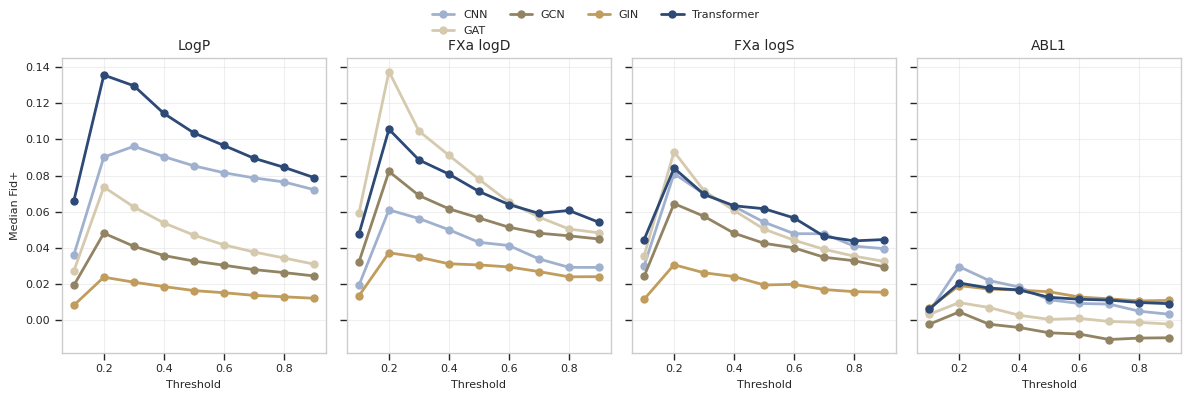

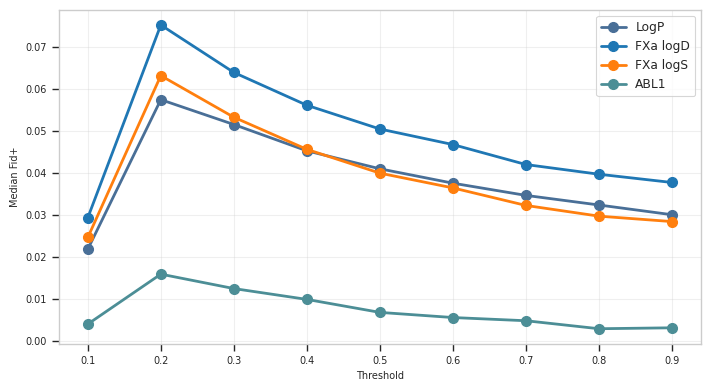

In [12]:
all_thres_data = [load_raw_data_all_thres(REAL_WORLD_RESULTS / folder, target_name, verbose=False)
                  for folder, target_name in REAL_WORLD_DATASETS.values()]
label_mapping = {'logp': 'LogP', 'logd': 'FXa logD', 'logs': 'FXa logS', 'abl1': 'ABL1'}
plot_fidelity_by_threshold_per_target(all_thres_data, label_mapping, figsize=(12, 4),
                                      save_path=OUTPUT_DIR / 'fid_by_threshold_analysis_per_target.pdf')
plot_fidelity_by_threshold(all_thres_data, REAL_WORLD_TARGET_COLORS, label_mapping, figsize=(7.2, 4),
                           save_path=OUTPUT_DIR / 'fid_by_threshold_analysis.pdf');

## Summary table

In [13]:
variance_df = combine_and_calculate_variance(table_data)
variance_df.to_latex(
    OUTPUT_DIR / 'supplementary_fid_variance_table.tex',
    index=False,
    float_format='%.3f',
    column_format='lllrllll',
    caption=(
        'Summary of normalized F-Fid$^+$ statistics across all model--method--target '
        'combinations. The table reports mean, median, standard deviation, and variance '
        'of normalized F-Fid$^+$ values across molecules for each configuration.'
    ),
    label='tab:supp_fid_variation',
    escape=False,
)
variance_df

,model,explanation_method,target,n,mean,median,std,var
76,GCN,SHAP,FXA logD,500,0.580,0.816,0.569,0.323
24,GAT,GNNExplainer,FXA logD,500,0.578,0.805,0.603,0.364
25,GAT,GNNExplainer,FXA logS,500,0.505,0.778,0.623,0.388
88,GIN,IG,FXA logD,500,0.474,0.764,0.643,0.413
100,GIN,SHAP,FXA logD,500,0.482,0.761,0.632,0.400
...,...,...,...,...,...,...,...,...
35,GAT,KernelSHAP,ABL1,685,-0.119,-0.211,0.664,0.441
81,GIN,GNNExplainer,FXA logS,500,-0.136,-0.221,0.723,0.522
27,GAT,GraphMask,ABL1,685,-0.118,-0.222,0.666,0.444
80,GIN,GNNExplainer,FXA logD,500,-0.216,-0.371,0.725,0.526


## OLS analysis

`normalized_fid ~ model * explanation_method + target_name` with SEs clustered by molecule. The first entry of each order is the baseline (GIN / GCN, IG, logP).

In [ ]:
OLS_SPECS = {
    'supplementary_fid_effect_size_table': {
        'model_order': ['GIN', 'GAT', 'GCN', 'Transformer', 'CNN'],
        'method_order': ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap'],
        'target_order': ['logp', 'logd', 'logs', 'abl1'],
    },
    'supplementary_fid_effect_size_table_graph': {
        'model_order': ['GIN', 'GCN', 'GAT'],
        'method_order': ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap', 'gnn_explainer', 'graph_mask'],
        'target_order': ['logp', 'abl1', 'logd', 'logs'],
    },
    'supplementary_fid_effect_size_table_conv': {
        'model_order': ['GCN', 'CNN'],
        'method_order': ['integrated_gradients', 'shap_sampling', 'lime', 'kernel_shap', 'grad_cam', 'guided_grad_cam'],
        'target_order': ['logp', 'abl1', 'logd', 'logs'],
    },
}
ols_models = {}
for name, spec in OLS_SPECS.items():
    ols_models[name] = fit_fid_ols(table_data, **spec)
    display(ols_models[name].summary())
    effect_sizes = compute_effect_sizes(ols_models[name])
    effect_sizes.to_latex(OUTPUT_DIR / f'{name}.tex', float_format='%.4f')
    display(effect_sizes)

171,700 samples


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         normalized_fid   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     511.6
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:45:17   Log-Likelihood:            -1.7215e+05
No. Observations:              171700   AIC:                         3.443e+05
Df Residuals:                  171677   BIC:                         3.446e+05
Df Model:                          22                                         
Covariance Type:              cluster                                         
============================================================================================================================
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept                                                    0.2895      0.008     35.667      0.000       0.274       0.305
model[T.GAT]                                                 0.2203      0.009     23.425      0.000       0.202       0.239
model[T.GCN]                                                 0.1250      0.010     13.089      0.000       0.106       0.144
model[T.Transformer]                                        -0.0218      0.011     -2.009      0.045      -0.043      -0.001
model[T.CNN]                                                -0.0843      0.010     -8.036      0.000      -0.105      -0.064
explanation_method[T.shap_sampling]                          0.1642      0.007     21.918      0.000       0.149       0.179
explanation_method[T.lime]                                  -0.2399      0.009    -26.875      0.000      -0.257      -0.222
explanation_method[T.kernel_shap]                           -0.3355      0.009    -36.167      0.000      -0.354      -0.317
target_name[T.logd]                                         -0.0147      0.013     -1.097      0.273      -0.041       0.012
target_name[T.logs]                                         -0.0490      0.014     -3.452      0.001      -0.077      -0.021
target_name[T.abl1]                                         -0.1582      0.012    -12.870      0.000      -0.182      -0.134
model[T.GAT]:explanation_method[T.shap_sampling]            -0.1756      0.009    -18.936      0.000      -0.194      -0.157
model[T.GCN]:explanation_method[T.shap_sampling]            -0.1319      0.010    -13.678      0.000      -0.151      -0.113
model[T.Transformer]:explanation_method[T.shap_sampling]    -0.1586      0.009    -16.797      0.000      -0.177      -0.140
model[T.CNN]:explanation_method[T.shap_sampling]            -0.0988      0.010    -10.263      0.000      -0.118      -0.080
model[T.GAT]:explanation_method[T.lime]                     -0.2256      0.011    -19.630      0.000      -0.248      -0.203
model[T.GCN]:explanation_method[T.lime]                     -0.1075      0.012     -9.202      0.000      -0.130      -0.085
model[T.Transformer]:explanation_method[T.lime]              0.1062      0.011      9.416      0.000       0.084       0.128
model[T.CNN]:explanation_method[T.lime]                      0.1777      0.011     16.076      0.000       0.156       0.199
model[T.GAT]:explanation_method[T.kernel_shap]              -0.1665      0.012    -13.879      0.000      -0.190      -0.143
model[T.GCN]:explanation_method[T.kernel_shap]              -0.0895      0.012     -7.421      0.000      -0.113      -0.066
model[T.Transformer]:explanation_method[T.kernel_shap]       0.1042      0.012     

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
model,76.891633,4.0,44.193968,1.125937e-36,0.000499,0.001029
explanation_method,3395.435774,3.0,2602.065167,0.000000e+00,0.022043,0.043493
target_name,75.350332,3.0,57.744127,7.577587e-37,0.000489,0.001008
model:explanation_method,1144.663448,12.0,219.300930,0.000000e+00,0.007431,0.015097
Residual,74673.793042,171677.0,NaN,NaN,0.484769,0.500000


154,530 samples


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         normalized_fid   R-squared:                       0.103
Model:                            OLS   Adj. R-squared:                  0.102
Method:                 Least Squares   F-statistic:                     584.1
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:45:18   Log-Likelihood:            -1.5748e+05
No. Observations:              154530   AIC:                         3.150e+05
Df Residuals:                  154509   BIC:                         3.152e+05
Df Model:                          20                                         
Covariance Type:              cluster                                         
====================================================================================================================
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                                            0.2844      0.008     34.885      0.000       0.268       0.300
model[T.GCN]                                         0.1250      0.010     13.089      0.000       0.106       0.144
model[T.GAT]                                         0.2203      0.009     23.425      0.000       0.202       0.239
explanation_method[T.shap_sampling]                  0.1642      0.007     21.918      0.000       0.149       0.179
explanation_method[T.lime]                          -0.2399      0.009    -26.875      0.000      -0.257      -0.222
explanation_method[T.kernel_shap]                   -0.3355      0.009    -36.167      0.000      -0.354      -0.317
explanation_method[T.gnn_explainer]                 -0.2518      0.010    -26.382      0.000      -0.271      -0.233
explanation_method[T.graph_mask]                    -0.3647      0.010    -38.068      0.000      -0.384      -0.346
target_name[T.abl1]                                 -0.1464      0.013    -11.246      0.000      -0.172      -0.121
target_name[T.logd]                                  0.0214      0.015      1.475      0.140      -0.007       0.050
target_name[T.logs]                                 -0.0133      0.016     -0.828      0.407      -0.045       0.018
model[T.GCN]:explanation_method[T.shap_sampling]    -0.1319      0.010    -13.678      0.000      -0.151      -0.113
model[T.GAT]:explanation_method[T.shap_sampling]    -0.1756      0.009    -18.936      0.000      -0.194      -0.157
model[T.GCN]:explanation_method[T.lime]             -0.1075      0.012     -9.202      0.000      -0.130      -0.085
model[T.GAT]:explanation_method[T.lime]             -0.2256      0.011    -19.630      0.000      -0.248      -0.203
model[T.GCN]:explanation_method[T.kernel_shap]      -0.0895      0.012     -7.421      0.000      -0.113      -0.066
model[T.GAT]:explanation_method[T.kernel_shap]      -0.1665      0.012    -13.879      0.000      -0.190      -0.143
model[T.GCN]:explanation_method[T.gnn_explainer]    -0.2429      0.013    -19.284      0.000      -0.268      -0.218
model[T.GAT]:explanation_method[T.gnn_explainer]     0.0670      0.012      5.715      0.000       0.044       0.090
model[T.GCN]:explanation_method[T.graph_mask]       -0.1330      0.012    -10.761      0.000      -0.157      -0.109
model[T.GAT]:explanation_method[T.graph_mask]       -0.2430      0.012    -19.702      0.000      -0.267      -0.219
==============================================================================
Omnibus:                    24726.019   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             6468.594
Skew:                          -0.196 

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
model,113.987546,2.0,126.782384,9.031214e-55,0.000791,0.001638
explanation_method,4151.981012,5.0,1847.212506,0.000000e+00,0.028809,0.056405
target_name,60.106859,3.0,44.569143,1.643544e-28,0.000417,0.000865
model:explanation_method,876.407829,10.0,194.956516,0.000000e+00,0.006081,0.012461
Residual,69458.000343,154509.0,NaN,NaN,0.481951,0.500000


102,289 samples


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         normalized_fid   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     448.8
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:45:18   Log-Likelihood:            -1.0137e+05
No. Observations:              102289   AIC:                         2.028e+05
Df Residuals:                  102274   BIC:                         2.029e+05
Df Model:                          14                                         
Covariance Type:              cluster                                         
======================================================================================================================
                                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------
Intercept                                              0.4127      0.008     54.923      0.000       0.398       0.427
model[T.CNN]                                          -0.2093      0.010    -21.623      0.000      -0.228      -0.190
explanation_method[T.shap_sampling]                    0.0323      0.006      5.143      0.000       0.020       0.045
explanation_method[T.lime]                            -0.3475      0.008    -42.789      0.000      -0.363      -0.332
explanation_method[T.kernel_shap]                     -0.4250      0.008    -50.316      0.000      -0.442      -0.408
explanation_method[T.grad_cam]                        -0.2484      0.008    -29.379      0.000      -0.265      -0.232
explanation_method[T.guided_grad_cam]                 -0.1506      0.008    -17.969      0.000      -0.167      -0.134
target_name[T.abl1]                                   -0.1672      0.013    -12.873      0.000      -0.193      -0.142
target_name[T.logd]                                    0.0044      0.016      0.283      0.777      -0.026       0.035
target_name[T.logs]                                   -0.0263      0.017     -1.507      0.132      -0.060       0.008
model[T.CNN]:explanation_method[T.shap_sampling]       0.0331      0.009      3.739      0.000       0.016       0.050
model[T.CNN]:explanation_method[T.lime]                0.2853      0.010     27.602      0.000       0.265       0.306
model[T.CNN]:explanation_method[T.kernel_shap]         0.2227      0.011     20.060      0.000       0.201       0.244
model[T.CNN]:explanation_method[T.grad_cam]           -0.0188      0.012     -1.573      0.116      -0.042       0.005
model[T.CNN]:explanation_method[T.guided_grad_cam]    -0.0479      0.011     -4.193      0.000      -0.070      -0.025
==============================================================================
Omnibus:                    17342.733   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4690.027
Skew:                          -0.242   Prob(JB):                         0.00
Kurtosis:                       2.070   Cond. No.                         17.9
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (cluster)
"""

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
model,138.276901,1.0,325.376991,4.597297e-71,0.001545,0.003171
explanation_method,1796.055887,5.0,845.253625,0.000000e+00,0.020068,0.039683
target_name,71.777321,3.0,56.299326,6.194314e-36,0.000802,0.001649
model:explanation_method,566.932792,5.0,266.807955,6.667786e-261,0.006334,0.012876
Residual,43463.834840,102274.0,NaN,NaN,0.485626,0.500000


In [15]:
compute_effect_sizes(ols_models['supplementary_fid_effect_size_table'], typ=3)

,sum_sq,df,F,PR(>F),eta_sq,eta_sq_partial
Intercept,553.345092,1.0,1272.154814,2.918692e-255,0.003611,0.007356
model,536.814349,4.0,308.537551,5.594825e-244,0.003503,0.007137
explanation_method,1567.335737,3.0,1201.115261,0.000000e+00,0.010229,0.020558
target_name,75.350332,3.0,57.744127,7.577587e-37,0.000492,0.001008
model:explanation_method,1144.663448,12.0,219.300930,0.000000e+00,0.007470,0.015097
Residual,74673.793042,171677.0,NaN,NaN,0.487347,0.500000


In [16]:
for name in ('supplementary_fid_effect_size_table_graph', 'supplementary_fid_effect_size_table_conv'):
    print(ols_models[name].summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}                                     & normalized\_fid  & \textbf{  R-squared:         } &      0.103   \\
\textbf{Model:}                                             &       OLS        & \textbf{  Adj. R-squared:    } &      0.102   \\
\textbf{Method:}                                            &  Least Squares   & \textbf{  F-statistic:       } &      584.1   \\
\textbf{Date:}                                              & Fri, 09 Oct 2026 & \textbf{  Prob (F-statistic):} &      0.00    \\
\textbf{Time:}                                              &     12:45:18     & \textbf{  Log-Likelihood:    } & -1.5748e+05  \\
\textbf{No. Observations:}                                  &      154530      & \textbf{  AIC:               } &  3.150e+05   \\
\textbf{Df Residuals:}                                      &      154509      & \textbf{  BIC:               } &  3.152e+05   \\
\textbf{Df Model:}                          

## Molecule count and size per dataset

In [17]:
summarize_molecule_stats({
    'LogP': REAL_WORLD_DATA / 'logp' / 'cleaned_and_filtered' / 'filtered_data.csv',
    'FXA_logD': REAL_WORLD_DATA / 'FXa_logs_logd_stratified' / 'cleaned_and_filtered' / 'filtered_data.csv',
    'FXA_logS': REAL_WORLD_DATA / 'FXa_logs_logd_stratified' / 'cleaned_and_filtered' / 'filtered_data.csv',
    'ABL1': REAL_WORLD_DATA / 'ABL1_pki' / 'cleaned_and_filtered' / 'filtered_data.csv',
})

,dataset,n_molecules,mean_num_atoms,std_num_atoms
0,LogP,13792,16.85,6.69
1,FXA_logD,997,35.57,4.26
2,FXA_logS,997,35.57,4.26
3,ABL1,1366,27.40,5.71


## Kruskal-Wallis tests (model, method, target)

In [18]:
for group_cols in (['model', 'target'], ['explanation_method', 'target'], ['target']):
    display(kruskal_by(table_data, group_cols))

,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by model x target),2064.767489,0.0,20,256819,0.007966,"[CNN_ABL1, CNN_FXA logD, CNN_FXA logS, CNN_Log..."


,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by explanation_method x target),15944.112019,0.0,32,256819,0.06197,"[gnn_explainer_ABL1, gnn_explainer_FXA logD, g..."


,test_name,H_statistic,p_value,n_groups,N,eta_squared,groups
0,Kruskal–Wallis (by target),805.278292,3.100931e-174,4,256819,0.003124,"[ABL1, FXA logD, FXA logS, LogP]"
